# Capstone Project: Unsupervised Machine Learning

## US Arrests -- PCA and Clustering

Exploring the relationships between violent crime rates and urban population share across the 50 US states (1973 data), using principal component analysis (PCA) and clustering.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Consistent plot styling
sns.set_style('whitegrid')


1. Load and explore the data

In [2]:
def load_data(filepath):
    """Load the US Arrests dataset and use the state name as the index."""
    data = pd.read_csv(filepath)
    data = data.rename(columns={'City': 'State'})
    data = data.set_index('State')
    return data


arrests = load_data('UsArrests.csv')
print(f"Shape: {arrests.shape}")
arrests.head()


Shape: (50, 4)


In [3]:
# Check data types and confirm there are no missing values
arrests.info()
print()
print("Missing values per column:")
print(arrests.isna().sum())


<class 'pandas.DataFrame'>
Index: 50 entries, Alabama to Wyoming
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Murder    50 non-null     float64
 1   Assault   50 non-null     int64  
 2   UrbanPop  50 non-null     int64  
 3   Rape      50 non-null     float64
dtypes: float64(2), int64(2)
memory usage: 2.0+ KB

Missing values per column:
Murder      0
Assault     0
UrbanPop    0
Rape        0
dtype: int64


In [ ]:
# Summary statistics
arrests.describe()

**Observations:**
- The dataset has 50 rows and no missing values, so no imputation is needed.
- The four variables sit on very different scales: `UrbanPop` is a percentage (roughly 30-100), `Assault` is in the hundreds, while `Murder` and `Rape` are single/low double-digit arrest rates. PCA is based on variance, so a variable measured on a larger numeric scale (like `Assault`) would dominate the principal components because of its scale, not because it's more informative. This motivates standardising the variables before running PCA or clustering, so that each variable contributes to its correlation structure rather than its raw units.

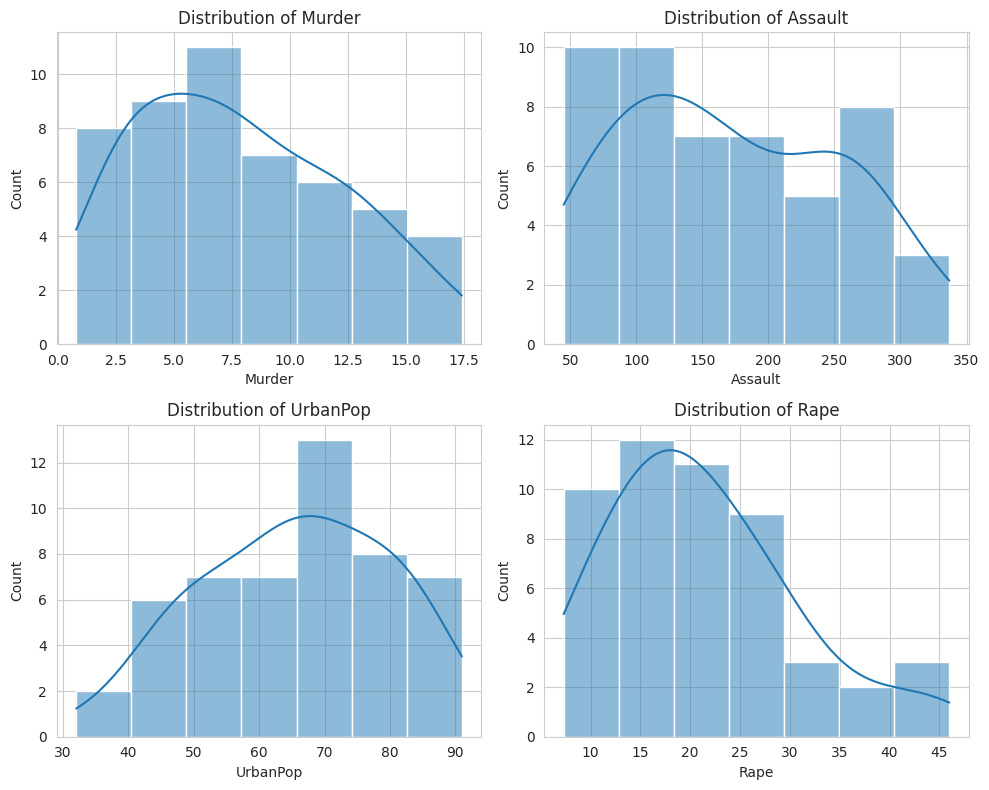

In [5]:
# Visualise the distributions of each variable
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.flatten(), arrests.columns):
    sns.histplot(arrests[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()


2. Correlation analysis

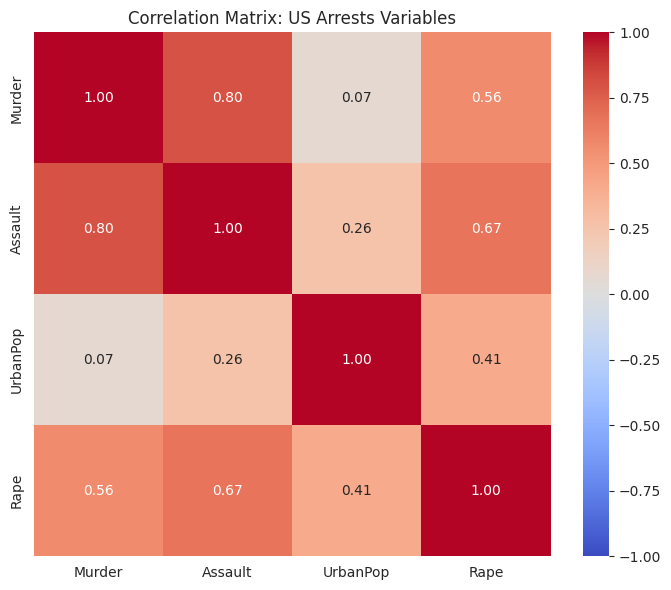

In [6]:
# Compute and visualise the correlation matrix
corr_matrix = arrests.corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation Matrix: US Arrests Variables')
plt.tight_layout()
plt.show()

corr_matrix


**Interpretation:**
- `Murder`, `Assault`, and `Rape` are all fairly strongly, positively correlated with one another (the strongest being `Murder`-`Assault`). This makes sense: states with more violent crime of one type tend to have more of the others too, so these three variables are capturing a largely overlapping 'overall violent crime' signal.
- `UrbanPop` correlates much more weakly with the crime variables. Urbanisation appears to be a largely separate dimension of variation in this dataset, rather than a strong driver of the crime rates.
- Because `Murder`, `Assault`, and `Rape` are correlated with each other, there is redundant information across them -- exactly the kind of structure PCA is well suited to compress into a smaller number of uncorrelated components.

3. Standardise the data and run PCA

In [7]:
# Standardise the features (mean 0, std 1) before PCA, as motivated above
scaler = StandardScaler()
arrests_scaled = scaler.fit_transform(arrests)
arrests_scaled_df = pd.DataFrame(
    arrests_scaled, columns=arrests.columns, index=arrests.index
)

arrests_scaled_df.describe().round(2)


In [8]:
# Fit PCA on the standardised data, keeping all components for now
pca = PCA()
principal_components = pca.fit_transform(arrests_scaled)

pc_columns = [f'PC{i+1}' for i in range(principal_components.shape[1])]
pc_df = pd.DataFrame(principal_components, columns=pc_columns, index=arrests.index)

print("Explained variance ratio per component:")
for name, ratio in zip(pc_columns, pca.explained_variance_ratio_):
    print(f"  {name}: {ratio:.3f} ({ratio*100:.1f}%)")

print(f"\nCumulative explained variance: {np.cumsum(pca.explained_variance_ratio_).round(3)}")


Explained variance ratio per component:
  PC1: 0.620 (62.0%)
  PC2: 0.247 (24.7%)
  PC3: 0.089 (8.9%)
  PC4: 0.043 (4.3%)

Cumulative explained variance: [0.62  0.868 0.957 1.   ]


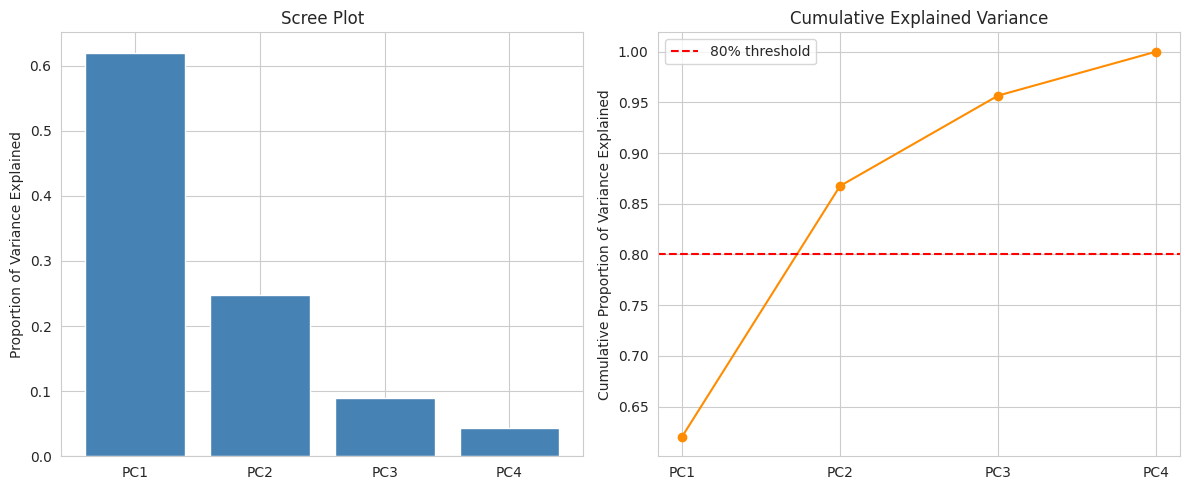

In [9]:
# Scree plot: variance explained by each component
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(pc_columns, pca.explained_variance_ratio_, color='steelblue')
axes[0].set_ylabel('Proportion of Variance Explained')
axes[0].set_title('Scree Plot')

axes[1].plot(pc_columns, np.cumsum(pca.explained_variance_ratio_), marker='o', color='darkorange')
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% threshold')
axes[1].set_ylabel('Cumulative Proportion of Variance Explained')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend()

plt.tight_layout()
plt.show()


4. Biplot of the first two principal components

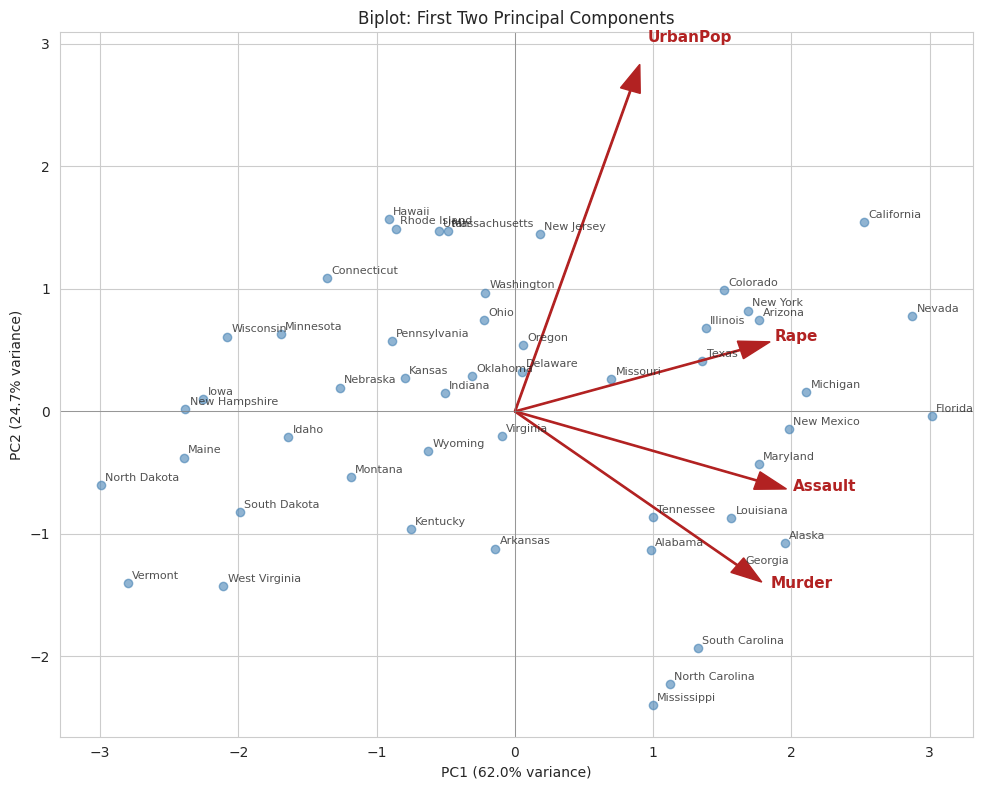

In [ ]:
def biplot(scores, loadings, labels, feature_names, pc_x=0, pc_y=1, scale=1.0):
    """
    Plot a PCA biplot: sample scores as points (labelled), and the
    original feature loading vectors as arrows.
    """
    fig, ax = plt.subplots(figsize=(10, 8))

    # Plot the states as points, labelled by name
    ax.scatter(scores[:, pc_x], scores[:, pc_y], alpha=0.6, color='steelblue')
    for i, label in enumerate(labels):
        ax.annotate(label, (scores[i, pc_x], scores[i, pc_y]),
                    fontsize=8, alpha=0.8, xytext=(3, 3), textcoords='offset points')

    # Plot the feature loading vectors, scaled up for visibility
    for i, feature in enumerate(feature_names):
        ax.arrow(0, 0, loadings[i, pc_x] * scale, loadings[i, pc_y] * scale,
                  color='firebrick', width=0.01, head_width=0.15)
        ax.text(loadings[i, pc_x] * scale * 1.15, loadings[i, pc_y] * scale * 1.15,
                feature, color='firebrick', fontsize=11, fontweight='bold')

    ax.axhline(0, color='grey', linewidth=0.5)
    ax.axvline(0, color='grey', linewidth=0.5)
    ax.set_xlabel(f'PC{pc_x + 1} ({pca.explained_variance_ratio_[pc_x]*100:.1f}% variance)')
    ax.set_ylabel(f'PC{pc_y + 1} ({pca.explained_variance_ratio_[pc_y]*100:.1f}% variance)')
    ax.set_title('Biplot: First Two Principal Components')
    plt.tight_layout()
    plt.show()


#pca.components_.T, rows = features, columns = components
biplot(principal_components, pca.components_.T, arrests.index, arrests.columns, scale=3)


**Interpretation of the biplot:**
- The three crime variables (`Murder`, `Assault`, `Rape`) point in similar directions, largely along **PC1** -- consistent with the positive correlations we saw earlier. States far to the right on PC1 (e.g. Florida, Nevada, California) have high rates across all three crime types; states far to the left (e.g. North Dakota, Vermont, Maine) have low rates across all three.
- `UrbanPop` points in a clearly different direction, dominating **PC2**. This confirms urbanisation is a largely independent axis of variation from overall violent crime rate: some states are highly urban with relatively low crime (e.g. Rhode Island, Massachusetts), while others are more rural with higher crime (e.g. Mississippi), and vice versa.
- In short, **PC1 can be read as an overall 'violent crime' axis**, and **PC2 as an 'urbanisation' axis**, and together they summarise most of the structure in the original four variables.

5. Choosing the number of principal components

In [11]:
# Summarise the case for how many components to retain
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

summary = pd.DataFrame({
    'Component': pc_columns,
    'Variance Explained': explained.round(3),
    'Cumulative Variance': cumulative.round(3)
})
summary


The scree plot shows a clear 'elbow' after the second component -- PC1 and PC2 explain the large majority of the variance, while PC3 and PC4 each add only a small increase. Retaining **2 principal components** is therefore a reasonable choice: it captures majority of the variation in the original four variables and matches the natural interpretation we found in the biplot , and lets one work in 2D for visualisation and clustering without losing much information.

In [12]:
# Keep the first 2 principal components for the downstream analyses
n_components = 2
pca_reduced_df = pc_df.iloc[:, :n_components]
pca_reduced_df.head()


6. Clustering

We apply two different clustering techniques -- **K-Means** and **Agglomerative (hierarchical) clustering** -- to the standardised data, and use the silhouette score to help choose a sensible number of clusters for each.

k=2: silhouette score = 0.408
k=3: silhouette score = 0.308
k=4: silhouette score = 0.340
k=5: silhouette score = 0.301
k=6: silhouette score = 0.294
k=7: silhouette score = 0.274


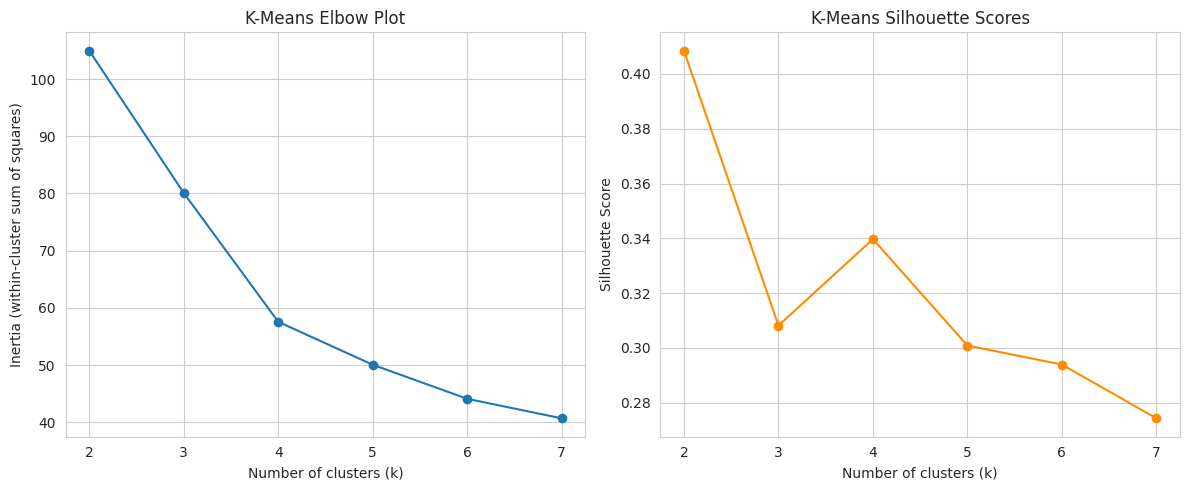

In [13]:
def evaluate_kmeans(data, k_range):
    """Fit K-Means for a range of k and return inertia and silhouette scores."""
    inertias = []
    silhouettes = []
    for k in k_range:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(data)
        inertias.append(model.inertia_)
        silhouettes.append(silhouette_score(data, labels))
    return inertias, silhouettes


k_range = range(2, 8)
inertias, silhouettes = evaluate_kmeans(arrests_scaled, k_range)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('K-Means Elbow Plot')

axes[1].plot(list(k_range), silhouettes, marker='o', color='darkorange')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('K-Means Silhouette Scores')

plt.tight_layout()
plt.show()

for k, sil in zip(k_range, silhouettes):
    print(f"k={k}: silhouette score = {sil:.3f}")


Choosing k: the silhouette score is highest at k = 2 (the cleanest, most well-separated split), while the elbow plot keeps improving noticeably up to around k = 4 before the gains flatten out. There's a genuine trade-off here: k = 2 gives the strongest mathematical separation (essentially 'higher-crime' vs 'lower-crime' states), while k = 4 is a reasonable grouping that better matches the range of states in the data. Proceed with k = 4, since it offers a richer basis for comparing clusters while still being supported by a respectable silhouette score, but note k = 2 as the statistically 'cleanest' alternative.

In [14]:
# Fit the final K-Means model with k = 4
k_final = 4
kmeans_model = KMeans(n_clusters=k_final, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(arrests_scaled)

arrests['KMeans_Cluster'] = kmeans_labels
print(f"K-Means silhouette score (k={k_final}): {silhouette_score(arrests_scaled, kmeans_labels):.3f}")
arrests[['Murder', 'Assault', 'UrbanPop', 'Rape', 'KMeans_Cluster']].sort_values('KMeans_Cluster')


K-Means silhouette score (k=4): 0.340


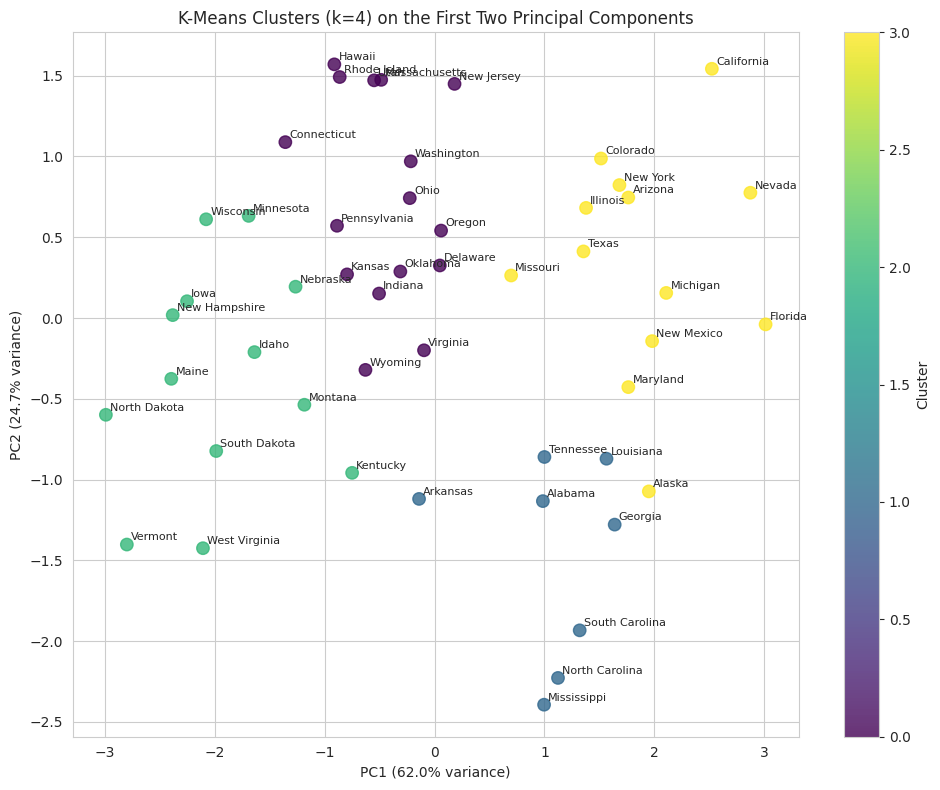

In [15]:
# Visualise the K-Means clusters on the first two principal components
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    principal_components[:, 0], principal_components[:, 1],
    c=kmeans_labels, cmap='viridis', s=80, alpha=0.8
)
for i, state in enumerate(arrests.index):
    plt.annotate(state, (principal_components[i, 0], principal_components[i, 1]),
                 fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title(f'K-Means Clusters (k={k_final}) on the First Two Principal Components')
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()


In [16]:
# Profile each K-Means cluster by its average crime/urbanisation rates
kmeans_profile = arrests.groupby('KMeans_Cluster')[['Murder', 'Assault', 'UrbanPop', 'Rape']].mean().round(1)
kmeans_profile['n_states'] = arrests.groupby('KMeans_Cluster').size()
kmeans_profile


Interpreting the K-Means clusters: the cluster means above let us characterise each group -- typically one cluster contains states with high rates across all crime types, another contains low-crime, often more rural states, and the remaining clusters fall in between, sometimes distinguished more by `UrbanPop` than by crime rate. States grouped together in the same cluster have similar combinations of murder, assault, rape, and urbanisation rates -- which is exactly what we'd expect given that PC1 (crime) and PC2 (urbanisation) are the two dominant axes we identified earlier.

Hierarchical (Agglomerative) clustering

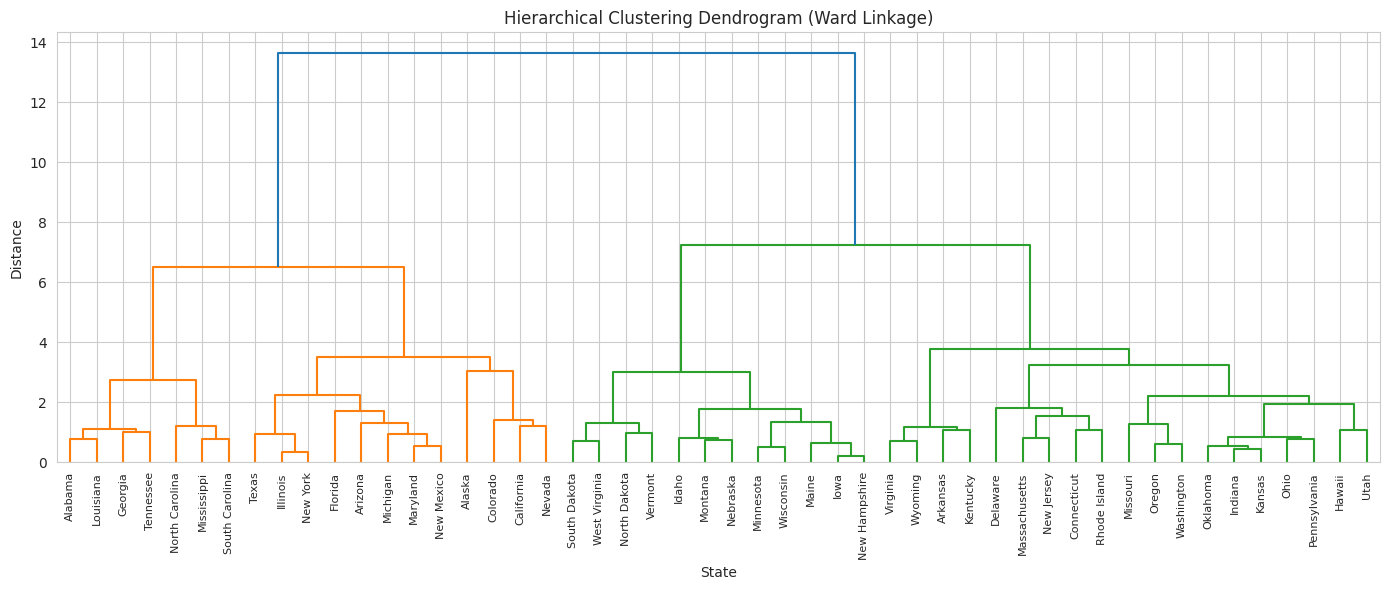

In [17]:
# Build a dendrogram using Ward linkage to visualise the hierarchical structure
linked = linkage(arrests_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(linked, labels=arrests.index.tolist(), leaf_rotation=90, leaf_font_size=8)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('State')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()


k=2: silhouette score = 0.405
k=3: silhouette score = 0.310
k=4: silhouette score = 0.337
k=5: silhouette score = 0.273
k=6: silhouette score = 0.262
k=7: silhouette score = 0.260


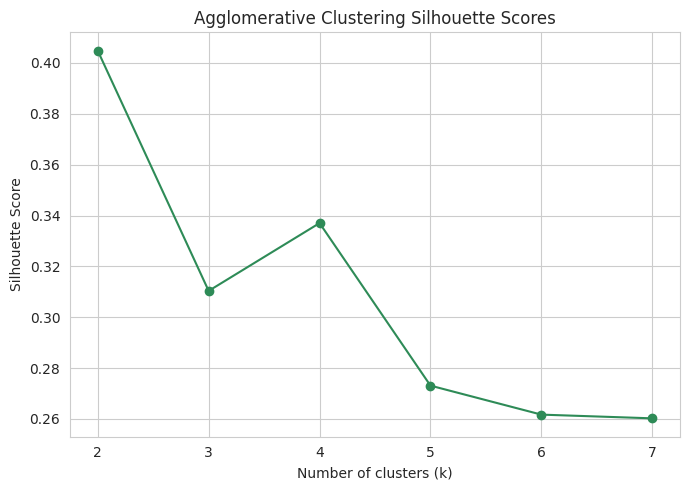

In [18]:
# Evaluate silhouette scores for agglomerative clustering across a range of k
agglo_silhouettes = []
for k in k_range:
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(arrests_scaled)
    agglo_silhouettes.append(silhouette_score(arrests_scaled, labels))

plt.figure(figsize=(7, 5))
plt.plot(list(k_range), agglo_silhouettes, marker='o', color='seagreen')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Agglomerative Clustering Silhouette Scores')
plt.tight_layout()
plt.show()

for k, sil in zip(k_range, agglo_silhouettes):
    print(f"k={k}: silhouette score = {sil:.3f}")


For consistency and comparability with the K-Means analysis above, and since the dendrogram visually supports a small number of well-defined branches around this range, we also use **k = 4** clusters for agglomerative clustering.

In [19]:
# Fit the final Agglomerative Clustering model with k = 4
agglo_model = AgglomerativeClustering(n_clusters=k_final, linkage='ward')
agglo_labels = agglo_model.fit_predict(arrests_scaled)

arrests['Agglomerative_Cluster'] = agglo_labels
print(f"Agglomerative silhouette score (k={k_final}): {silhouette_score(arrests_scaled, agglo_labels):.3f}")
arrests[['Murder', 'Assault', 'UrbanPop', 'Rape', 'Agglomerative_Cluster']].sort_values('Agglomerative_Cluster')


Agglomerative silhouette score (k=4): 0.337


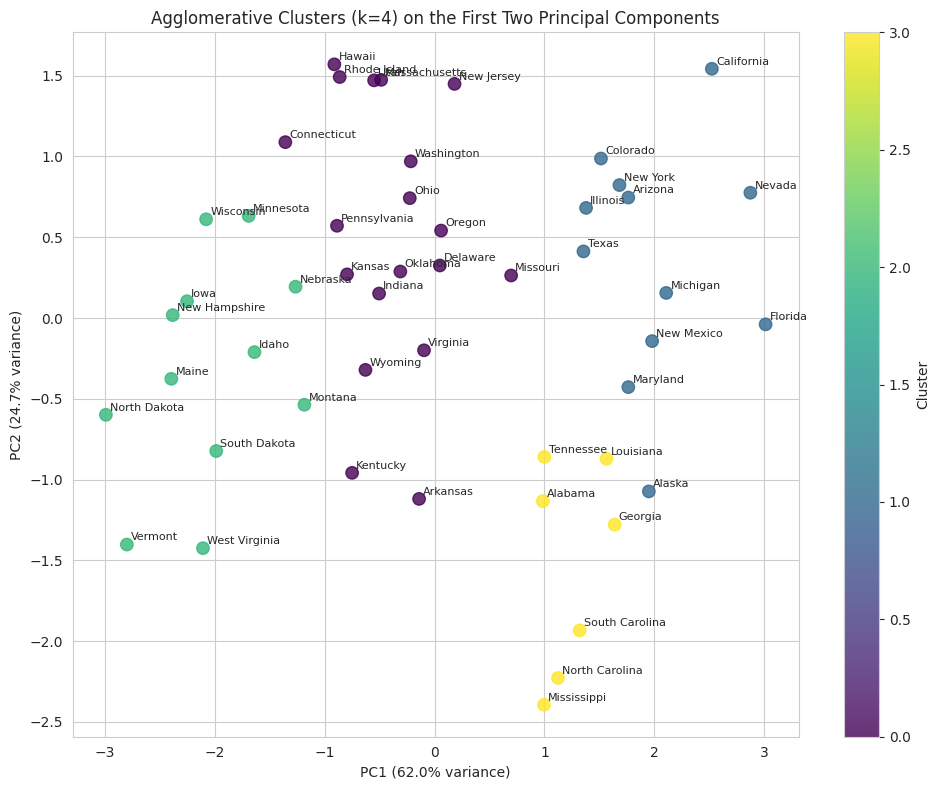

In [20]:
# Visualise the Agglomerative clusters on the first two principal components
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    principal_components[:, 0], principal_components[:, 1],
    c=agglo_labels, cmap='viridis', s=80, alpha=0.8
)
for i, state in enumerate(arrests.index):
    plt.annotate(state, (principal_components[i, 0], principal_components[i, 1]),
                 fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title(f'Agglomerative Clusters (k={k_final}) on the First Two Principal Components')
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()


In [21]:
# Profile each Agglomerative cluster
agglo_profile = arrests.groupby('Agglomerative_Cluster')[['Murder', 'Assault', 'UrbanPop', 'Rape']].mean().round(1)
agglo_profile['n_states'] = arrests.groupby('Agglomerative_Cluster').size()
agglo_profile


In [22]:
# Compare how often the two clustering methods agree on groupings
comparison_table = pd.crosstab(arrests['KMeans_Cluster'], arrests['Agglomerative_Cluster'])
comparison_table.index.name = 'K-Means Cluster'
comparison_table.columns.name = 'Agglomerative Cluster'
comparison_table


Comparing the Two Clustering Methods:
Comparing K-Means and Agglomerative clustering shows strong agreement overall. When both algorithms put the same states into the same group, it confirms that the patterns in the data are real rather than just a result of the algorithm used. Differences only pop up for "borderline" states—those with average crime and urbanization levels that could fit into either group.

Overall Pattern:
Both methods divide the states in the exact same way as the PCA results:
High-crime cluster: Groups states with high rates of murder, assault, and rape (such as Georgia, Mississippi, Nevada, and Florida).
Low-crime cluster: Groups safer states together (such as North Dakota, New Hampshire, Maine, and Iowa).
The state profiles within each group closely match their overall crime levels (PC1) and urbanization (PC2), confirming that the clustering effectively captured the underlying patterns in the data

7. Summary of findings

- `Murder`, `Assault`, and `Rape` are positively correlated with one another, while `UrbanPop` varies largely independently of them.
- Standardising the data before PCA was necessary because the raw variables are on very different scales (`Assault` is measured in the hundreds; the others are much smaller).
- The first two principal components explain the large majority of the variance and have a clean interpretation: **PC1 is an overall 'violent crime' axis**, and **PC2 is an 'urbanisation' axis**.
- Both K-Means and hierarchical clustering group the states similarly: high-crime states group together, low-crime states group together, and middle groups are separated mostly by their urbanization level.
Because two different methods produce almost the same results, we can be confident these groups represent real patterns in the 1973 US data rather than just a fluke of the algorithm.